# Project 2: Concrete Compressive Strength Prediction
**Objective:** predict concrete compressive strength (MPa) from mixture ingredients and curing age.

The notebook compares a mean baseline, a linear regression model and nonlinear tree-based regressors. A held-out test set is used for final performance and residual diagnostics.

In [1]:
import warnings, os
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
RANDOM_STATE=42
DATA_PATH=os.path.join("data","Concrete_Data.csv")
df=pd.read_csv(DATA_PATH)
print("Shape:",df.shape)
display(df.head())
print(df.info())
display(df.describe().T.round(3))
print("Missing cells:",int(df.isna().sum().sum()))

Shape: (1030, 9)


,Cement (kg in a m^3 mixture),Blast Furnace Slag (kg in a m^3 mixture),Fly Ash (kg in a m^3 mixture),Water (kg in a m^3 mixture),Superplasticizer (kg in a m^3 mixture),Coarse Aggregate (kg in a m^3 mixture),Fine Aggregate (kg in a m^3 mixture),Age (day),"Concrete compressive strength (MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   Cement (kg in a m^3 mixture)                       1030 non-null   float64
 1   Blast Furnace Slag (kg in a m^3 mixture)           1030 non-null   float64
 2   Fly Ash (kg in a m^3 mixture)                      1030 non-null   float64
 3   Water (kg in a m^3 mixture)                        1030 non-null   float64
 4   Superplasticizer (kg in a m^3 mixture)             1030 non-null   float64
 5   Coarse Aggregate (kg in a m^3 mixture)             1030 non-null   float64
 6   Fine Aggregate (kg in a m^3 mixture)               1030 non-null   float64
 7   Age (day)                                          1030 non-null   int64  
 8   Concrete compressive strength (MPa, megapascals)   1030 non-null   float64
dtypes: float6

,count,mean,std,min,25%,50%,75%,max
Cement (kg in a m^3 mixture),1030.0,281.166,104.507,102.000,192.375,272.900,350.000,540.000
Blast Furnace Slag (kg in a m^3 mixture),1030.0,73.895,86.279,0.000,0.000,22.000,142.950,359.400
Fly Ash (kg in a m^3 mixture),1030.0,54.187,63.996,0.000,0.000,0.000,118.270,200.100
Water (kg in a m^3 mixture),1030.0,181.566,21.356,121.750,164.900,185.000,192.000,247.000
Superplasticizer (kg in a m^3 mixture),1030.0,6.203,5.973,0.000,0.000,6.350,10.160,32.200
Coarse Aggregate (kg in a m^3 mixture),1030.0,972.919,77.754,801.000,932.000,968.000,1029.400,1145.000
Fine Aggregate (kg in a m^3 mixture),1030.0,773.579,80.175,594.000,730.950,779.510,824.000,992.600
Age (day),1030.0,45.662,63.170,1.000,7.000,28.000,56.000,365.000
"Concrete compressive strength (MPa, megapascals)",1030.0,35.818,16.706,2.332,23.707,34.443,46.136,82.599


Missing cells: 0


## 1. Data exploration and preparation
The dataset contains eight quantitative predictors: cement, blast furnace slag, fly ash, water, superplasticizer, coarse aggregate, fine aggregate and age. The outcome is compressive strength in MPa. The supplied data has 1,030 rows and no missing values. No categorical encoding is needed. All predictors are retained because they represent mixture composition and curing age. Scaling is applied for the linear model; tree models do not require feature scaling.

,Compressive strength (MPa)
count,1030.000000
mean,35.817836
std,16.705679
min,2.331808
25%,23.707115
50%,34.442774
75%,46.136287
max,82.599225


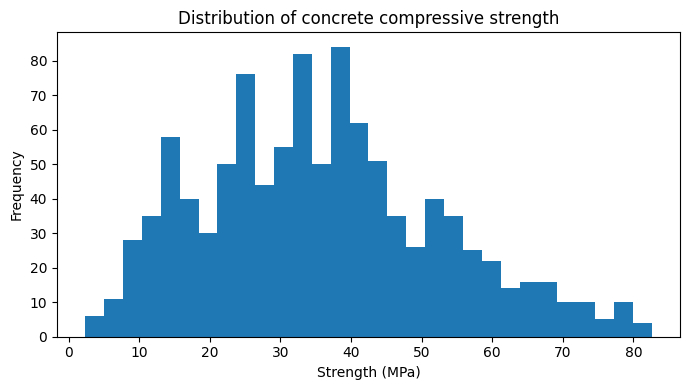

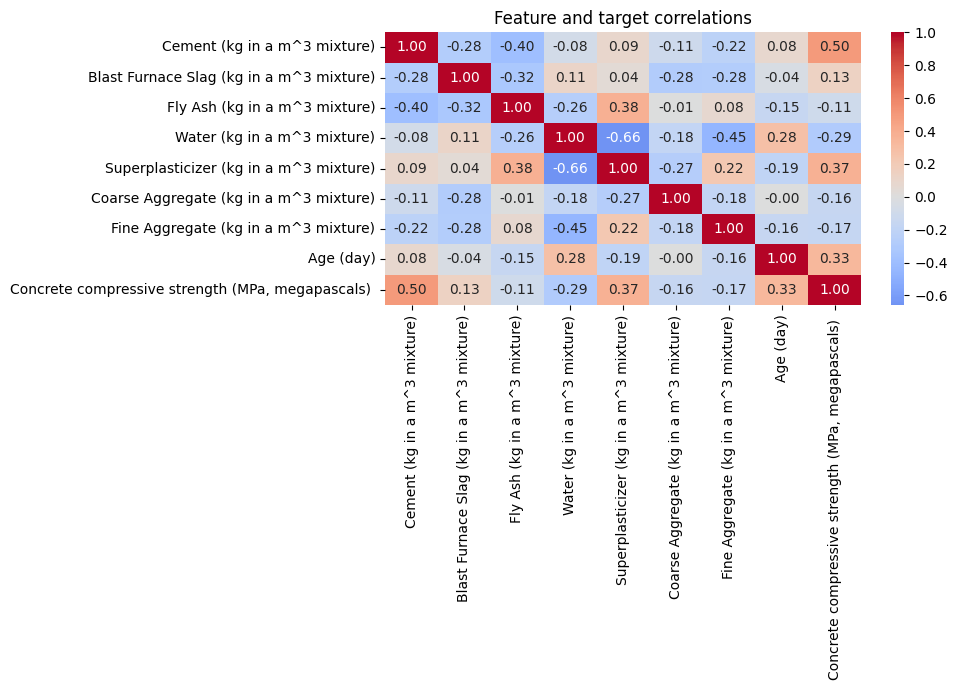

In [2]:
target=df.columns[-1]
X=df.drop(columns=[target]); y=df[target]
display(y.describe().to_frame("Compressive strength (MPa)"))
plt.figure(figsize=(7,4)); plt.hist(y,bins=30); plt.title("Distribution of concrete compressive strength"); plt.xlabel("Strength (MPa)"); plt.ylabel("Frequency"); plt.tight_layout(); plt.show()
plt.figure(figsize=(10,7)); sns.heatmap(df.corr(numeric_only=True),annot=True,fmt=".2f",cmap="coolwarm",center=0); plt.title("Feature and target correlations"); plt.tight_layout(); plt.show()

## 2. Baseline and split
A mean-prediction baseline predicts the mean strength of the training set for every test observation. MAE and RMSE measure typical and larger errors in MPa; R² measures the fraction of test-set variance explained relative to predicting the test mean. The split is 80% training and 20% testing, with a fixed seed for reproducibility.

In [3]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=RANDOM_STATE)
baseline_pred=np.repeat(y_train.mean(),len(y_test))
def regression_metrics(actual,pred):
    return {"MAE (MPa)":mean_absolute_error(actual,pred),
            "RMSE (MPa)":np.sqrt(mean_squared_error(actual,pred)),
            "R2":r2_score(actual,pred)}
baseline_metrics=regression_metrics(y_test,baseline_pred)
display(pd.Series(baseline_metrics,name="Mean baseline").to_frame())

,Mean baseline
MAE (MPa),13.052409
RMSE (MPa),16.053687
R2,-0.000154


## 3. Linear and nonlinear model comparison
- **Linear regression:** interpretable additive linear benchmark; scaling helps numerical stability but does not change ordinary least-squares fitted predictions.
- **Random forest:** bagged decision trees capture nonlinear response curves and interactions.
- **Extra Trees:** highly randomized tree ensemble, often effective on small tabular datasets.
- **Histogram gradient boosting:** sequentially fits trees to reduce errors and captures nonlinear structure.

All models are trained on the same training set and evaluated on the same untouched test set. Lower MAE/RMSE and higher R² indicate better predictions.

In [4]:
models={
 "Linear regression":Pipeline([("imputer",SimpleImputer(strategy="median")),("scale",StandardScaler()),("model",LinearRegression())]),
 "Random forest":Pipeline([("imputer",SimpleImputer(strategy="median")),("model",RandomForestRegressor(n_estimators=400,min_samples_leaf=2,max_features=1.0,n_jobs=-1,random_state=RANDOM_STATE))]),
 "Extra Trees":Pipeline([("imputer",SimpleImputer(strategy="median")),("model",ExtraTreesRegressor(n_estimators=400,min_samples_leaf=2,n_jobs=-1,random_state=RANDOM_STATE))]),
 "HistGradientBoosting":Pipeline([("imputer",SimpleImputer(strategy="median")),("model",HistGradientBoostingRegressor(max_iter=250,learning_rate=0.06,max_leaf_nodes=15,l2_regularization=1.0,random_state=RANDOM_STATE))])
}
fitted={}; results=[{"Model":"Mean baseline",**baseline_metrics}]
for name,model in models.items():
    model.fit(X_train,y_train)
    fitted[name]=model
    pred=model.predict(X_test)
    results.append({"Model":name,**regression_metrics(y_test,pred)})
results_df=pd.DataFrame(results).sort_values("RMSE (MPa)")
display(results_df)
best_name=results_df.loc[results_df.Model!="Mean baseline"].iloc[0].Model
best_model=fitted[best_name]
print("Best nonlinear/linear model by test RMSE:",best_name)

,Model,MAE (MPa),RMSE (MPa),R2
4,HistGradientBoosting,3.079442,4.354355,0.926419
3,Extra Trees,3.659338,5.355416,0.888698
2,Random forest,4.031620,5.685835,0.874540
1,Linear regression,7.745393,9.796708,0.627542
0,Mean baseline,13.052409,16.053687,-0.000154


Best nonlinear/linear model by test RMSE: HistGradientBoosting


## 4. Residual diagnostics and weakest predictions
Residual = actual strength − predicted strength. A good model should have residuals centered around zero, with no strong pattern against fitted values. A funnel shape suggests changing error variance; curved patterns suggest missed nonlinear structure. The largest absolute residuals identify observations where predictions are weakest. These may reflect unusual mixtures, age combinations, measurement noise or limitations of the available predictors.

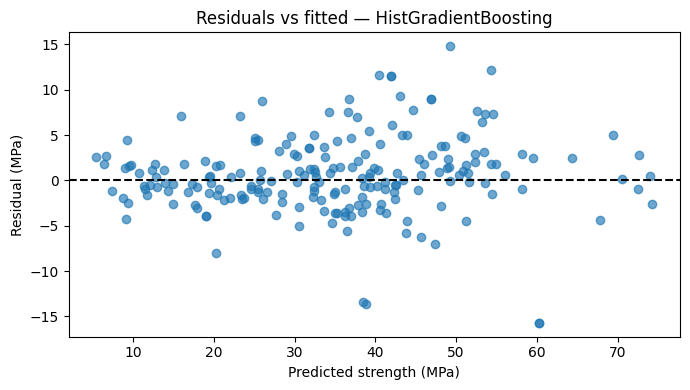

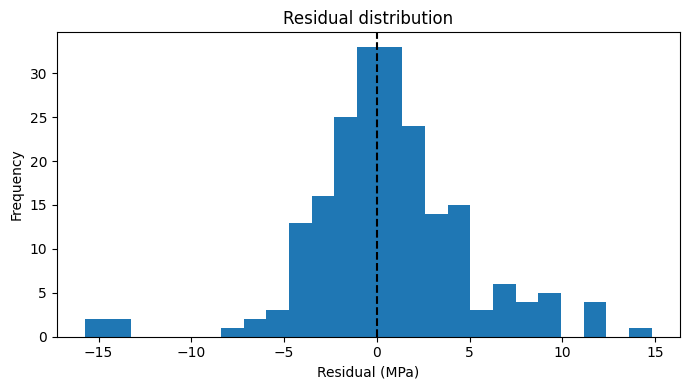

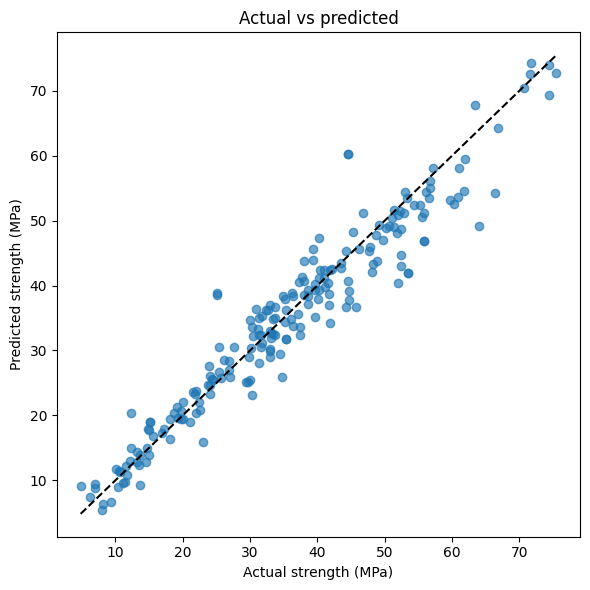

In [5]:
pred=best_model.predict(X_test)
residual=y_test.to_numpy()-pred
fig,ax=plt.subplots(figsize=(7,4)); ax.scatter(pred,residual,alpha=.65); ax.axhline(0,color="black",linestyle="--")
ax.set_xlabel("Predicted strength (MPa)"); ax.set_ylabel("Residual (MPa)"); ax.set_title(f"Residuals vs fitted — {best_name}"); plt.tight_layout(); plt.show()
plt.figure(figsize=(7,4)); plt.hist(residual,bins=25); plt.axvline(0,color="black",linestyle="--"); plt.title("Residual distribution"); plt.xlabel("Residual (MPa)"); plt.ylabel("Frequency"); plt.tight_layout(); plt.show()
plt.figure(figsize=(6,6)); plt.scatter(y_test,pred,alpha=.65); lim=[min(y_test.min(),pred.min()),max(y_test.max(),pred.max())]; plt.plot(lim,lim,"k--"); plt.xlabel("Actual strength (MPa)"); plt.ylabel("Predicted strength (MPa)"); plt.title("Actual vs predicted"); plt.tight_layout(); plt.show()

In [6]:
diagnostics=X_test.copy()
diagnostics["Actual_strength_MPa"]=y_test.to_numpy()
diagnostics["Predicted_strength_MPa"]=pred
diagnostics["Residual_MPa"]=residual
diagnostics["Absolute_error_MPa"]=np.abs(residual)
display(diagnostics.sort_values("Absolute_error_MPa",ascending=False).head(10))
print("Mean residual:",round(float(np.mean(residual)),4))
print("Median absolute error:",round(float(np.median(np.abs(residual))),4))

,Cement (kg in a m^3 mixture),Blast Furnace Slag (kg in a m^3 mixture),Fly Ash (kg in a m^3 mixture),Water (kg in a m^3 mixture),Superplasticizer (kg in a m^3 mixture),Coarse Aggregate (kg in a m^3 mixture),Fine Aggregate (kg in a m^3 mixture),Age (day),Actual_strength_MPa,Predicted_strength_MPa,Residual_MPa,Absolute_error_MPa
908,313.00,145.0,0.00,127.0,8.00,1000.0,822.00,28,44.519465,60.238050,-15.718585,15.718585
971,312.70,144.7,0.00,127.3,8.00,999.7,822.20,28,44.523602,60.238050,-15.714448,15.714448
382,505.00,0.0,60.00,195.0,0.00,1030.0,630.00,28,64.017847,49.207446,14.810400,14.810400
919,313.00,0.0,0.00,178.0,8.00,1000.0,822.00,28,25.096926,38.786947,-13.690021,13.690021
982,312.70,0.0,0.00,178.1,8.00,999.7,822.20,28,25.103821,38.533603,-13.429782,13.429782
333,246.83,0.0,125.08,143.3,11.99,1086.8,800.89,100,66.424118,54.265724,12.158394,12.158394
478,446.00,24.0,79.00,162.0,11.61,967.0,712.00,7,52.007175,40.417906,11.589269,11.589269
1001,297.80,137.2,106.90,201.3,6.00,878.4,655.30,28,53.524711,41.956593,11.568118,11.568118
844,298.00,137.0,107.00,201.0,6.00,878.0,655.00,28,53.524022,41.956593,11.567429,11.567429
1015,322.50,148.6,0.00,185.8,8.50,951.0,709.50,28,52.426376,43.091655,9.334722,9.334722


Mean residual: 0.62
Median absolute error: 2.0195


## 5. Cement content and causal interpretation
A correlation or predictive relationship between cement content and compressive strength does **not** prove what would happen if cement were deliberately increased. The dataset is observational: cement varies together with water, slag, fly ash, superplasticizer, aggregate proportions and curing age. Confounding, interactions, mixture constraints and unobserved production conditions can affect strength. A model estimates conditional patterns within the observed data; it does not automatically estimate the causal effect of an intervention.

To answer a real-world “what if cement is changed?” question, use controlled experiments or a well-designed causal study: vary cement while controlling other ingredients and curing conditions, randomise batches where feasible, replicate measurements, and respect engineering/material constraints. Predictions outside the observed mixture ranges are extrapolations and should not be trusted without validation.

## 6. Conclusions and responsible use
Report the best model using the displayed held-out metrics, and retain the baseline as a reference. The residual plots and worst-error table provide evidence about where predictions are least reliable. The dataset is relatively small and may not represent every cement source, aggregate type, climate, curing regime or construction practice. Before engineering use, validate on independent batches and report prediction uncertainty. A predictive model can support screening and planning, but should not replace required laboratory testing or engineering standards.